# 🌾 Seasonal Agriculture Performance Analysis
**VOIS AICTE Batch 1 (2026-2027) · Major Project · Data Analytics**

---
## 1. Problem Statement
Agricultural performance changes from one season to another because environmental conditions, farming practices, resource availability and market conditions change. Raw agricultural data does not, on its own, explain *how* performance shifts between seasons. This project analyses the dataset to uncover **meaningful seasonal patterns, trends, relationships and variations**.

## 2. Objectives
1. Explore, understand and clean the dataset.
2. Measure how agricultural performance (yield, productivity, profitability) varies across **Kharif, Rabi and Zaid**.
3. Investigate how environmental conditions and resource usage change between seasons.
4. Test relationships between seasonal conditions and outcomes.
5. Check whether seasonal patterns are consistent across crops, states and irrigation methods.
6. Identify unusual patterns and derive **evidence-based recommendations**.

## 3. Key Analytical Questions
| # | Question |
|---|---|
| Q1 | How does yield vary across seasons — and is the difference statistically significant? |
| Q2 | Is the seasonal pattern consistent across all crops? |
| Q3 | Which environmental characteristics change between seasons? |
| Q4 | Does resource usage (fertilizer, pesticide, water, cost) change between seasons? |
| Q5 | How do economic outcomes (profit, loss-making share) vary by season? |
| Q6 | Which environmental conditions relate to yield inside each season? |
| Q7 | Does irrigation method matter more in certain seasons? |
| Q8 | Are the patterns consistent across states? |
| Q9 | Are there unusual or unexpected patterns? |
| Q10 | How can findings support better seasonal planning? |

In [1]:
import warnings, os
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from itertools import combinations

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.titlesize': 12})

SEASON_ORDER = ['Kharif', 'Rabi', 'Zaid']
PALETTE = {'Kharif': '#2E7D32', 'Rabi': '#F9A825', 'Zaid': '#D84315'}
IMG_DIR = '../images'
os.makedirs(IMG_DIR, exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(f'{IMG_DIR}/{name}.png', dpi=150, bbox_inches='tight')

## 4. Data Loading & Exploration

In [2]:
df = pd.read_csv('../data/seasonal_agriculture_performance_dataset.csv')
print('Shape:', df.shape)
df.head()

Shape: (4000, 28)


,Farm_ID,State,District,Crop,Season,Farm_Area_Hectares,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,...,Seed_Quality_Score,Yield_Tonnes_Ha,Production_Tonnes,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct
0,SF10001,Andhra Pradesh,Rajkot,Wheat,Kharif,0.53,486.4,24.3,69.1,5.8,...,0.76,2.46,1.30,23700,42662,30810,-11852,237,5.485,55.3
1,SF10002,Maharashtra,Nalgonda,Maize,Kharif,6.53,855.4,25.7,78.4,5.1,...,0.94,0.30,1.96,20613,492351,40401,-451950,4953,0.396,49.9
2,SF10003,Telangana,Warangal,Pulses,Rabi,4.86,455.6,23.9,56.4,10.3,...,0.98,0.52,2.53,75283,315210,190466,-124744,1275,1.984,33.7
3,SF10004,Telangana,Indore,Rice,Kharif,4.50,753.2,29.7,65.2,6.3,...,0.74,1.84,8.28,24244,296444,200740,-95704,3834,2.160,50.6
4,SF10005,Karnataka,Ludhiana,Maize,Zaid,4.21,101.6,34.1,55.2,6.5,...,0.90,2.21,9.30,20818,337959,193607,-144352,3287,2.829,32.3


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 28 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Farm_ID                        4000 non-null   str    
 1   State                          4000 non-null   str    
 2   District                       4000 non-null   str    
 3   Crop                           4000 non-null   str    
 4   Season                         4000 non-null   str    
 5   Farm_Area_Hectares             4000 non-null   float64
 6   Rainfall_mm                    3952 non-null   float64
 7   Avg_Temperature_C              4000 non-null   float64
 8   Humidity_pct                   4000 non-null   float64
 9   Sunlight_Hours_Day             4000 non-null   float64
 10  Soil_pH                        4000 non-null   float64
 11  Soil_Moisture_pct              3960 non-null   float64
 12  Nitrogen_kg_ha                 4000 non-null   float64
 13 

In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Farm_Area_Hectares,4000.0,7.89,4.22,0.50,4.26,7.90,11.65,15.00
Rainfall_mm,3952.0,601.15,288.93,80.00,370.20,582.00,834.95,1395.20
Avg_Temperature_C,4000.0,26.82,3.82,16.20,23.90,26.90,29.60,39.70
Humidity_pct,4000.0,63.21,11.96,25.00,54.78,63.00,71.90,95.00
Sunlight_Hours_Day,4000.0,7.32,1.12,3.50,6.60,7.30,8.10,11.00
Soil_pH,4000.0,6.70,0.64,5.20,6.26,6.69,7.14,8.40
Soil_Moisture_pct,3960.0,26.51,6.71,8.00,21.70,26.40,31.30,47.00
Nitrogen_kg_ha,4000.0,120.25,31.22,40.00,98.50,120.10,141.22,220.00
Phosphorus_kg_ha,4000.0,57.78,17.02,15.00,46.20,57.50,69.40,120.00
Potassium_kg_ha,4000.0,104.76,27.74,30.00,86.20,105.10,123.60,200.00


In [5]:
# Categorical overview
for c in ['State', 'Crop', 'Season', 'Irrigation_Method']:
    print(f'--- {c} ---')
    print(df[c].value_counts().to_string(), '\n')

--- State ---
State
Andhra Pradesh    529
Telangana         516
Maharashtra       512
Madhya Pradesh    497
Karnataka         489
Gujarat           488
Tamil Nadu        485
Punjab            484 

--- Crop ---
Crop
Rice         690
Wheat        614
Maize        551
Cotton       508
Pulses       496
Groundnut    424
Chilli       412
Sugarcane    305 

--- Season ---
Season
Kharif    1779
Rabi      1627
Zaid       594 

--- Irrigation_Method ---
Irrigation_Method
Flood        1310
Rainfed      1041
Drip          915
Sprinkler     734 



## 5. Data Cleaning & Preparation

### 5.1 Missing values, duplicates and data-integrity checks

In [6]:
missing = df.isna().sum()
missing = missing[missing > 0].to_frame('Missing').assign(Pct=lambda x: (x.Missing / len(df) * 100).round(2))
print('Duplicate rows   :', df.duplicated().sum())
print('Duplicate Farm_ID:', df.Farm_ID.duplicated().sum())
missing

Duplicate rows   : 0
Duplicate Farm_ID: 0


,Missing,Pct
Rainfall_mm,48,1.2
Soil_Moisture_pct,40,1.0
Yield_Tonnes_Ha,32,0.8


In [7]:
# Are the derived financial/production columns internally consistent? (needed to justify imputation)
print('Production = Yield x Area  mismatches :', ((df.Yield_Tonnes_Ha * df.Farm_Area_Hectares - df.Production_Tonnes).abs() > 0.05).sum())
print('Revenue = Production x Price mismatches:', ((df.Production_Tonnes * df.Market_Price_INR_Tonne - df.Revenue_INR).abs() > 5).sum())
print('Profit = Revenue - Cost mismatches     :', ((df.Revenue_INR - df.Total_Cost_INR - df.Profit_INR).abs() > 2).sum())
print('Humidity outside 0-100                 :', (~df.Humidity_pct.between(0, 100)).sum())
print('Soil pH outside 3-10                   :', (~df.Soil_pH.between(3, 10)).sum())
print('Negative area / cost / water           :', ((df.Farm_Area_Hectares <= 0) | (df.Total_Cost_INR < 0) | (df.Water_Used_m3 < 0)).sum())

Production = Yield x Area  mismatches : 0
Revenue = Production x Price mismatches: 0
Profit = Revenue - Cost mismatches     : 0
Humidity outside 0-100                 : 0
Soil pH outside 3-10                   : 0
Negative area / cost / water           : 0


**Decisions**
- `Yield_Tonnes_Ha` (32 missing): `Production_Tonnes` is complete and equals *Yield × Area* exactly, so the missing yields are **recomputed** as `Production / Area` (no estimation needed).
- `Rainfall_mm` (48 missing) and `Soil_Moisture_pct` (40 missing): both vary strongly by season, so they are filled with the **season-wise median** (robust to outliers, and does not blur the seasonal signal).

In [8]:
clean = df.copy()
for c in ['State', 'District', 'Crop', 'Season', 'Irrigation_Method']:
    clean[c] = clean[c].str.strip().str.title()

# 1) Yield from production / area
n_yield = clean.Yield_Tonnes_Ha.isna().sum()
clean['Yield_Tonnes_Ha'] = clean.Yield_Tonnes_Ha.fillna(clean.Production_Tonnes / clean.Farm_Area_Hectares)

# 2) Season-wise median for environmental gaps
for c in ['Rainfall_mm', 'Soil_Moisture_pct']:
    clean[c] = clean[c].fillna(clean.groupby('Season')[c].transform('median'))

print(f'Yield values recomputed: {n_yield}')
print('Remaining missing values:', clean.isna().sum().sum())

Yield values recomputed: 32
Remaining missing values: 0


### 5.2 Outliers and geographic-consistency check

In [9]:
# Yield outliers are judged WITHIN each crop (Sugarcane naturally yields ~20-40x other crops)
def iqr_flags(g):
    q1, q3 = g.quantile([.25, .75]); i = q3 - q1
    return (g < q1 - 1.5 * i) | (g > q3 + 1.5 * i)

clean['Yield_Outlier'] = clean.groupby('Crop').Yield_Tonnes_Ha.transform(iqr_flags)
print('Within-crop yield outliers flagged:', clean.Yield_Outlier.sum(), f'({clean.Yield_Outlier.mean():.1%})')
print()
print(clean.groupby('Crop').Yield_Tonnes_Ha.agg(['count', 'mean', 'median', 'min', 'max']).round(2))

Within-crop yield outliers flagged: 1 (0.0%)

           count   mean  median   min     max
Crop                                         
Chilli       412   1.54    1.56  0.30    3.90
Cotton       508   1.22    1.24  0.30    2.90
Groundnut    424   1.32    1.40  0.30    3.02
Maize        551   2.71    2.85  0.30    6.08
Pulses       496   0.92    0.94  0.30    2.09
Rice         690   2.44    2.46  0.30    5.70
Sugarcane    305  46.93   48.03  1.39  101.44
Wheat        614   2.11    2.22  0.30    4.56


In [10]:
# District-State consistency
ds = clean.groupby('District').State.nunique()
print('Districts:', clean.District.nunique(), '| districts appearing under more than one state:', (ds > 1).sum())

Districts: 10 | districts appearing under more than one state: 10


**Decisions**
- Within-crop outliers are few and represent plausible high/low yields — they are **retained** (flagged in `Yield_Outlier`).
- **Sugarcane** is a *different scale* of crop (≈47 t/ha vs 1–3 t/ha). Comparing raw yield across seasons would therefore be distorted by the crop mix, so I use a **crop-normalised Yield Index** (below) for all cross-crop comparisons.
- The `District` column is **not reliable at state level** (the same district name appears under several states — the data is synthetic), so the geographic analysis is done at **State** level only.

### 5.3 Feature engineering

In [11]:
clean['Yield_Index']      = clean.Yield_Tonnes_Ha / clean.groupby('Crop').Yield_Tonnes_Ha.transform('mean')  # 1.0 = crop average
clean['Profit_per_ha']    = clean.Profit_INR / clean.Farm_Area_Hectares
clean['Cost_per_ha']      = clean.Total_Cost_INR / clean.Farm_Area_Hectares
clean['Revenue_per_ha']   = clean.Revenue_INR / clean.Farm_Area_Hectares
clean['Water_per_ha']     = clean.Water_Used_m3 / clean.Farm_Area_Hectares
clean['Loss_Making']      = (clean.Profit_INR < 0).astype(int)
clean['Season'] = pd.Categorical(clean.Season, SEASON_ORDER, ordered=True)

clean.to_csv('../data/cleaned_agriculture_data.csv', index=False)
print('Cleaned dataset saved ->', clean.shape)
clean[['Crop', 'Season', 'Yield_Tonnes_Ha', 'Yield_Index', 'Profit_per_ha', 'Water_per_ha', 'Loss_Making']].head()

Cleaned dataset saved -> (4000, 35)


,Crop,Season,Yield_Tonnes_Ha,Yield_Index,Profit_per_ha,Water_per_ha,Loss_Making
0,Wheat,Kharif,2.46,1.167193,-22362.264151,447.169811,1
1,Maize,Kharif,0.30,0.110572,-69211.332312,758.499234,1
2,Pulses,Rabi,0.52,0.567047,-25667.489712,262.345679,1
3,Rice,Kharif,1.84,0.755102,-21267.555556,852.000000,1
4,Maize,Zaid,2.21,0.814544,-34287.885986,780.760095,1


## 6. Seasonal Analysis
### Q1 · How does agricultural performance vary across seasons?
**Sample check first:** does each season contain a similar crop mix? If not, seasonal differences could just be a crop-mix effect.

In [12]:
print((pd.crosstab(clean.Crop, clean.Season, normalize='columns') * 100).round(1))
print()
print(clean.Season.value_counts().sort_index().to_string())

Season     Kharif  Rabi  Zaid
Crop                         
Chilli       10.4  10.0  10.8
Cotton       12.1  12.4  15.5
Groundnut    10.8  10.9   9.1
Maize        13.2  14.3  14.1
Pulses       12.4  13.1  10.4
Rice         17.7  16.8  17.2
Sugarcane     7.0   7.9   8.6
Wheat        16.4  14.6  14.3

Season
Kharif    1779
Rabi      1627
Zaid       594


The crop mix is nearly identical in each season (each crop ≈ same share), so seasonal differences are **not** a crop-mix artefact.

In [13]:
perf = clean.groupby('Season').agg(
    Farms=('Farm_ID', 'count'),
    Avg_Yield_t_ha=('Yield_Tonnes_Ha', 'mean'),
    Avg_Yield_Index=('Yield_Index', 'mean'),
    Median_Yield_Index=('Yield_Index', 'median'),
    Avg_Water_Eff=('Water_Efficiency_t_per_1000m3', 'mean'),
).round(3)
perf['Yield_Index_vs_Kharif_%'] = ((perf.Avg_Yield_Index / perf.loc['Kharif', 'Avg_Yield_Index'] - 1) * 100).round(1)
perf

,Farms,Avg_Yield_t_ha,Avg_Yield_Index,Median_Yield_Index,Avg_Water_Eff,Yield_Index_vs_Kharif_%
Season,,,,,,
Kharif,1779,5.629,1.110,1.165,5.892,0.0
Rabi,1627,5.093,0.957,0.992,5.186,-13.8
Zaid,594,4.633,0.789,0.817,4.413,-28.9


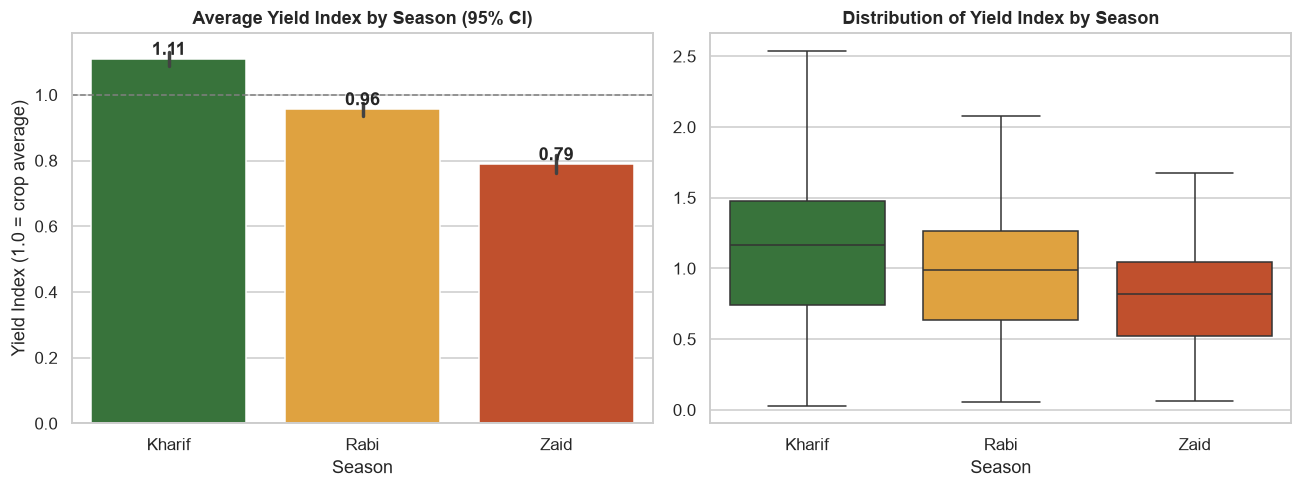

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
sns.barplot(data=clean, x='Season', y='Yield_Index', order=SEASON_ORDER, palette=PALETTE, hue='Season', hue_order=SEASON_ORDER, dodge=False, legend=False, errorbar=('ci', 95), ax=ax[0])
ax[0].axhline(1, ls='--', c='grey', lw=1); ax[0].set_title('Average Yield Index by Season (95% CI)')
ax[0].set_ylabel('Yield Index (1.0 = crop average)')
for p in ax[0].patches: ax[0].annotate(f'{p.get_height():.2f}', (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom', fontweight='bold')
sns.boxplot(data=clean, x='Season', y='Yield_Index', order=SEASON_ORDER, palette=PALETTE, hue='Season', hue_order=SEASON_ORDER, dodge=False, legend=False, showfliers=False, ax=ax[1])
ax[1].set_title('Distribution of Yield Index by Season'); ax[1].set_ylabel('')
save('01_yield_index_by_season'); plt.show()

In [15]:
# Statistical tests
groups = [clean.loc[clean.Season == s, 'Yield_Index'] for s in SEASON_ORDER]
h, p_kw = stats.kruskal(*groups)
f, p_an = stats.f_oneway(*groups)
grand = clean.Yield_Index.mean()
eta2 = sum(len(g) * (g.mean() - grand) ** 2 for g in groups) / ((clean.Yield_Index - grand) ** 2).sum()
print(f'Kruskal-Wallis  H = {h:.1f}, p = {p_kw:.2e}')
print(f'One-way ANOVA   F = {f:.1f}, p = {p_an:.2e}')
print(f'Effect size eta-squared = {eta2:.3f}  (season explains {eta2:.1%} of yield-index variance)\n')

rows = []
for a, b in combinations(SEASON_ORDER, 2):
    u, p = stats.mannwhitneyu(clean.loc[clean.Season == a, 'Yield_Index'], clean.loc[clean.Season == b, 'Yield_Index'])
    rows.append((f'{a} vs {b}', round(p * 3, 6)))   # Bonferroni x3
pd.DataFrame(rows, columns=['Pair', 'Bonferroni-adj p-value'])

Kruskal-Wallis  H = 256.4, p = 2.15e-56
One-way ANOVA   F = 129.0, p = 5.03e-55
Effect size eta-squared = 0.061  (season explains 6.1% of yield-index variance)



,Pair,Bonferroni-adj p-value
0,Kharif vs Rabi,0.0
1,Kharif vs Zaid,0.0
2,Rabi vs Zaid,0.0


**Insight Q1.** Yield Index falls steadily **Kharif (≈1.11) → Rabi (≈0.96) → Zaid (≈0.79)**. Zaid yields are ~29% below Kharif. Kruskal-Wallis, ANOVA and all three Bonferroni-adjusted pairwise tests are highly significant (p ≪ 0.001): the seasonal ranking is **real, not noise**.

### Q2 · Is the seasonal pattern consistent across crops?

Season     Kharif  Rabi  Zaid  Drop_Kharif_to_Zaid_%
Crop                                                
Pulses       1.13  0.95  0.70                  -37.6
Chilli       1.12  0.95  0.77                  -31.4
Cotton       1.12  0.97  0.77                  -31.2
Groundnut    1.12  0.93  0.79                  -30.0
Rice         1.11  0.95  0.78                  -29.8
Sugarcane    1.14  0.94  0.82                  -28.1
Maize        1.09  0.96  0.84                  -23.3
Wheat        1.07  0.98  0.83                  -22.3


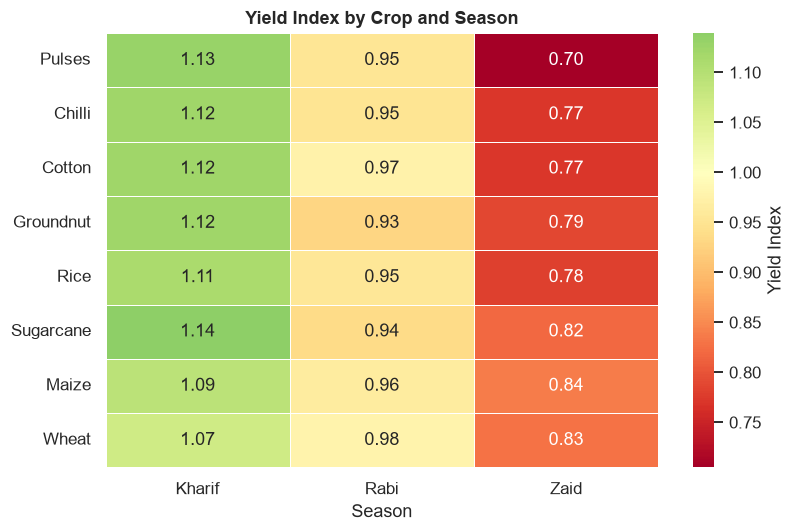

In [16]:
crop_season = clean.pivot_table(index='Crop', columns='Season', values='Yield_Index', aggfunc='mean')[SEASON_ORDER]
crop_season['Drop_Kharif_to_Zaid_%'] = ((crop_season.Zaid / crop_season.Kharif - 1) * 100).round(1)
crop_season = crop_season.sort_values('Drop_Kharif_to_Zaid_%')
print(crop_season.round(2).to_string())

fig, ax = plt.subplots(figsize=(7.5, 5))
sns.heatmap(crop_season[SEASON_ORDER], annot=True, fmt='.2f', cmap='RdYlGn', center=1, linewidths=.5, cbar_kws={'label': 'Yield Index'}, ax=ax)
ax.set_title('Yield Index by Crop and Season'); ax.set_ylabel('')
save('02_crop_season_yield_heatmap'); plt.show()

In [17]:
# Raw yield per crop (t/ha) for reference — Sugarcane shown separately because of scale
raw = clean.pivot_table(index='Crop', columns='Season', values='Yield_Tonnes_Ha', aggfunc='mean')[SEASON_ORDER].round(2)
raw

Season,Kharif,Rabi,Zaid
Crop,,,
Chilli,1.73,1.46,1.18
Cotton,1.37,1.19,0.94
Groundnut,1.48,1.23,1.04
Maize,2.97,2.62,2.28
Pulses,1.04,0.87,0.65
Rice,2.71,2.33,1.90
Sugarcane,53.46,43.95,38.42
Wheat,2.25,2.06,1.75


**Insight Q2.** All 8 crops show the same ordering **Kharif > Rabi > Zaid**, with a Kharif→Zaid drop of roughly 22–38% for every crop (largest for Pulses, smallest for Wheat). The seasonal effect is a **system-wide** feature, not driven by one or two crops.

### Q3 · Which environmental characteristics change between seasons?

In [18]:
env_cols = ['Rainfall_mm', 'Avg_Temperature_C', 'Humidity_pct', 'Sunlight_Hours_Day', 'Soil_Moisture_pct', 'Disease_Pest_Risk_pct']
env = clean.groupby('Season')[env_cols].mean().round(2)
pv = {c: stats.kruskal(*[clean.loc[clean.Season == s, c] for s in SEASON_ORDER]).pvalue for c in env_cols}
env.loc['Kruskal p-value'] = [f'{pv[c]:.1e}' for c in env_cols]
env

,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,Soil_Moisture_pct,Disease_Pest_Risk_pct
Season,,,,,,
Kharif,852.11,28.45,71.81,6.79,31.2,54.47
Rabi,435.94,23.49,57.89,7.59,24.05,40.48
Zaid,299.12,31.04,52.01,8.18,19.17,38.22
Kruskal p-value,0.0e+00,0.0e+00,0.0e+00,1.9e-181,0.0e+00,1.9e-311


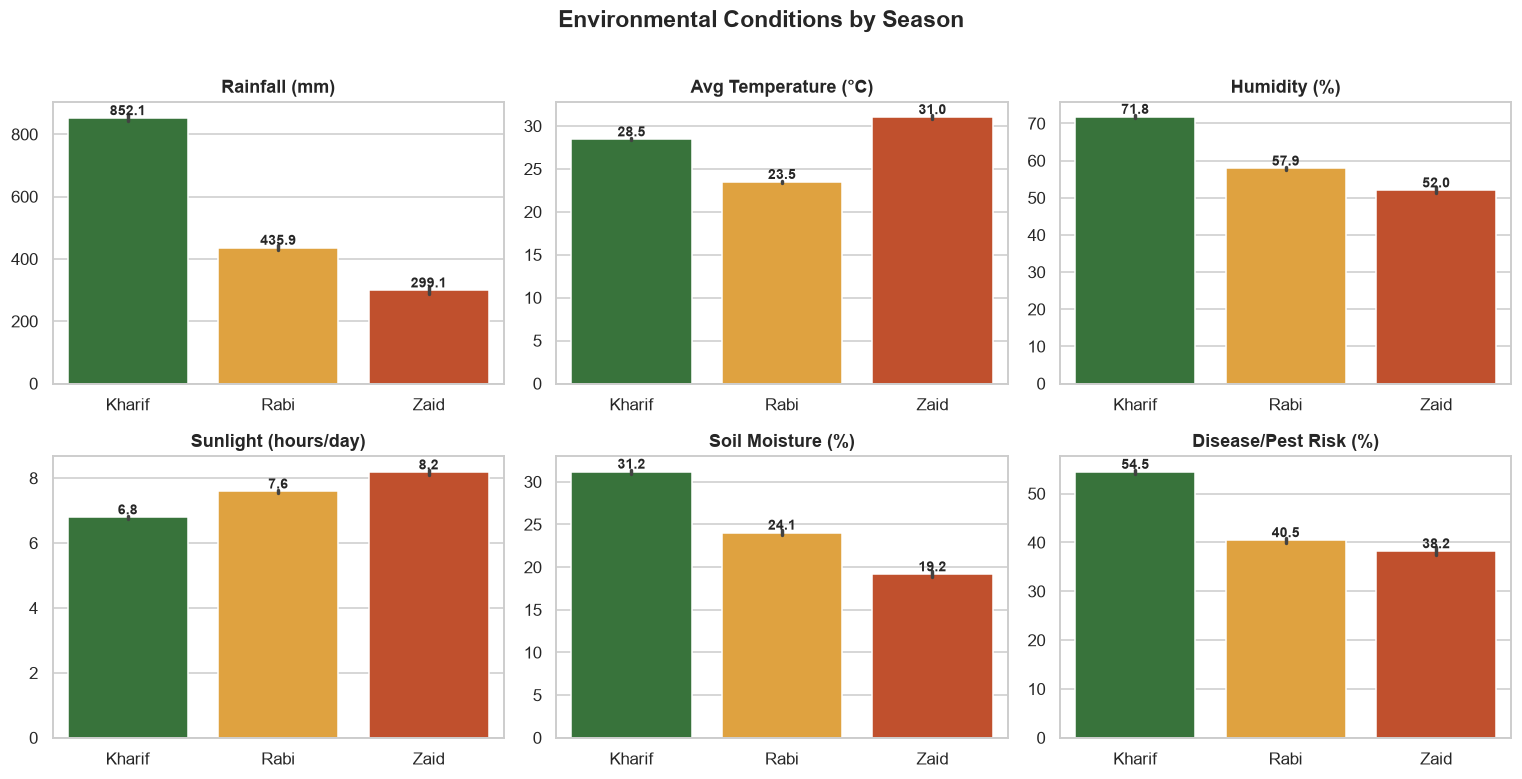

In [19]:
titles = {'Rainfall_mm': 'Rainfall (mm)', 'Avg_Temperature_C': 'Avg Temperature (°C)', 'Humidity_pct': 'Humidity (%)',
          'Sunlight_Hours_Day': 'Sunlight (hours/day)', 'Soil_Moisture_pct': 'Soil Moisture (%)', 'Disease_Pest_Risk_pct': 'Disease/Pest Risk (%)'}
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.ravel(), env_cols):
    sns.barplot(data=clean, x='Season', y=c, order=SEASON_ORDER, palette=PALETTE, hue='Season', hue_order=SEASON_ORDER, dodge=False, legend=False, errorbar=('ci', 95), ax=ax)
    ax.set_title(titles[c]); ax.set_xlabel(''); ax.set_ylabel('')
    for p in ax.patches: ax.annotate(f'{p.get_height():.1f}', (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom', fontsize=9, fontweight='bold')
plt.suptitle('Environmental Conditions by Season', fontsize=15, fontweight='bold', y=1.01)
save('03_environment_by_season'); plt.show()

**Insight Q3.** The three seasons are environmentally very different:
- **Kharif** – monsoon season: rainfall ≈ 852 mm, humidity ≈ 72%, soil moisture ≈ 31%, and the **highest disease/pest risk (≈ 54%)**.
- **Rabi** – cool and moderate: temperature ≈ 23.5 °C, rainfall ≈ 436 mm.
- **Zaid** – hot and dry: temperature ≈ 31 °C, rainfall ≈ 299 mm, soil moisture ≈ 19%, the most sunlight (≈ 8.2 h).

All differences are statistically significant (p ≈ 0).

### Q4 · Are there variations in resource usage across seasons?

In [20]:
res_cols = ['Fertilizer_kg_ha', 'Pesticide_Litre_ha', 'Water_per_ha', 'Cost_per_ha', 'Seed_Quality_Score']
res = clean.groupby('Season')[res_cols].mean().round(2)
res.loc['Kruskal p-value'] = [f"{stats.kruskal(*[clean.loc[clean.Season == s, c] for s in SEASON_ORDER]).pvalue:.2f}" for c in res_cols]
res

,Fertilizer_kg_ha,Pesticide_Litre_ha,Water_per_ha,Cost_per_ha,Seed_Quality_Score
Season,,,,,
Kharif,187.08,5.08,758.17,66900.98,0.82
Rabi,185.41,5.02,763.36,66295.24,0.83
Zaid,184.64,5.17,792.58,66937.94,0.82
Kruskal p-value,0.59,0.31,0.20,0.08,0.01


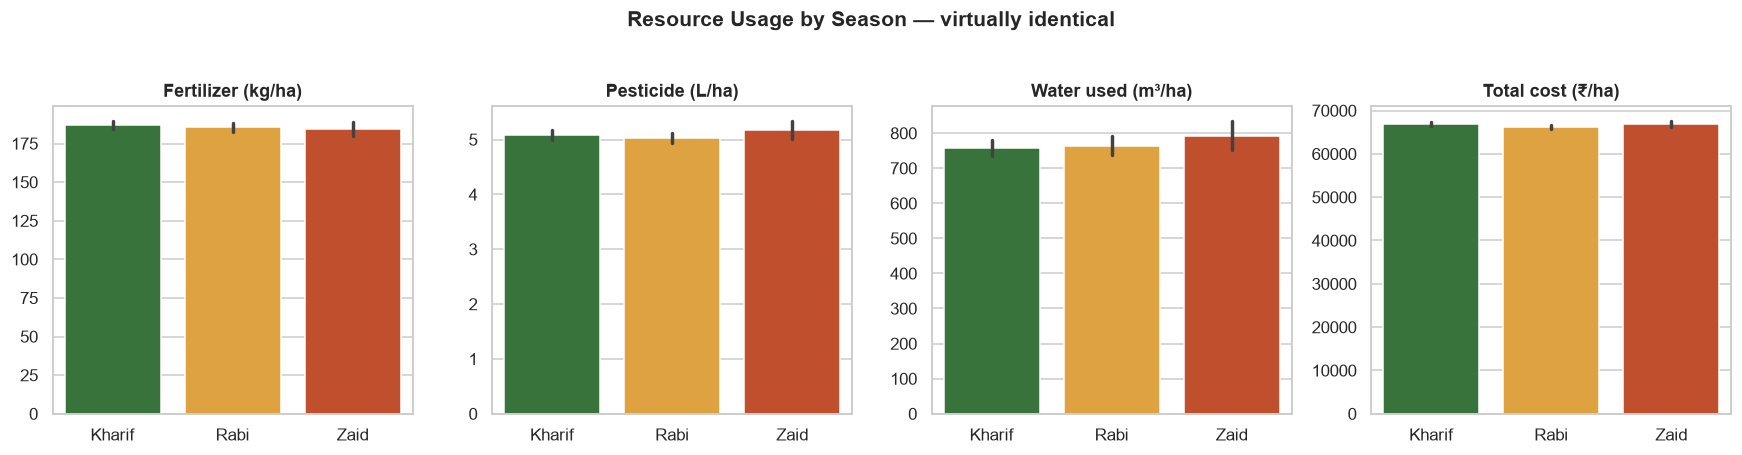

In [21]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (c, t) in zip(axes, [('Fertilizer_kg_ha', 'Fertilizer (kg/ha)'), ('Pesticide_Litre_ha', 'Pesticide (L/ha)'),
                             ('Water_per_ha', 'Water used (m³/ha)'), ('Cost_per_ha', 'Total cost (₹/ha)')]):
    sns.barplot(data=clean, x='Season', y=c, order=SEASON_ORDER, palette=PALETTE, hue='Season', hue_order=SEASON_ORDER, dodge=False, legend=False, errorbar=('ci', 95), ax=ax)
    ax.set_title(t); ax.set_xlabel(''); ax.set_ylabel('')
plt.suptitle('Resource Usage by Season — virtually identical', fontsize=14, fontweight='bold', y=1.03)
save('04_resource_use_by_season'); plt.show()

**Insight Q4 (important).** Fertilizer, pesticide, water per hectare and cost per hectare are **statistically the same in every season** (p > 0.05). Farmers apply the same inputs in all seasons even though conditions differ sharply. Yet Zaid (hot, dry) produces far less → **the same inputs are converting to lower output in Zaid**, meaning input usage is not adapted to season.

### Q5 · How do economic outcomes vary across seasons?

In [22]:
eco = clean.groupby('Season').agg(
    Avg_Price_INR_t=('Market_Price_INR_Tonne', 'mean'),
    Avg_Revenue_per_ha=('Revenue_per_ha', 'mean'),
    Avg_Profit_per_ha=('Profit_per_ha', 'mean'),
    Median_Profit_per_ha=('Profit_per_ha', 'median'),
    Loss_Making_Share_pct=('Loss_Making', lambda x: x.mean() * 100),
).round(1)
eco

,Avg_Price_INR_t,Avg_Revenue_per_ha,Avg_Profit_per_ha,Median_Profit_per_ha,Loss_Making_Share_pct
Season,,,,,
Kharif,44850.9,88782.8,21881.8,8340.4,42.2
Rabi,44748.0,76656.9,10361.7,-894.3,51.1
Zaid,44212.0,64301.4,-2636.5,-13760.3,64.5


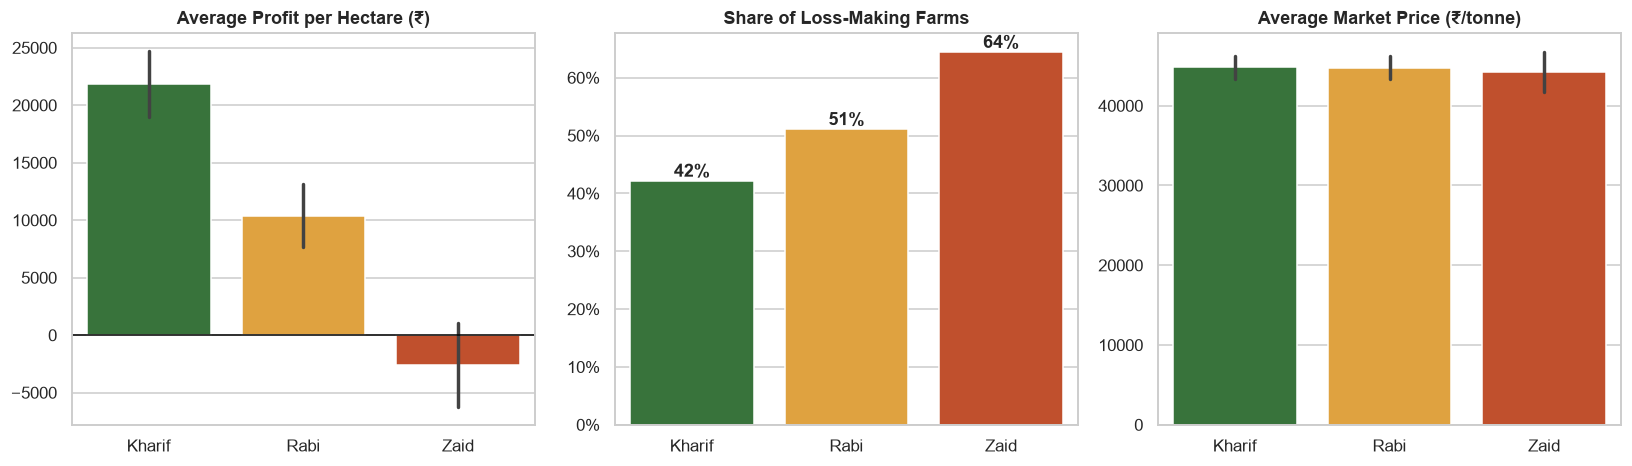

Kruskal p (profit/ha): 8.10e-22
Kruskal p (price)    : 0.94


In [23]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
sns.barplot(data=clean, x='Season', y='Profit_per_ha', order=SEASON_ORDER, palette=PALETTE, hue='Season', hue_order=SEASON_ORDER, dodge=False, legend=False, errorbar=('ci', 95), ax=ax[0])
ax[0].axhline(0, c='black', lw=1); ax[0].set_title('Average Profit per Hectare (₹)'); ax[0].set_ylabel('')
sns.barplot(data=clean, x='Season', y='Loss_Making', order=SEASON_ORDER, palette=PALETTE, hue='Season', hue_order=SEASON_ORDER, dodge=False, legend=False, errorbar=None, ax=ax[1])
ax[1].set_title('Share of Loss-Making Farms'); ax[1].set_ylabel(''); ax[1].yaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
for p in ax[1].patches: ax[1].annotate(f'{p.get_height():.0%}', (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom', fontweight='bold')
sns.barplot(data=clean, x='Season', y='Market_Price_INR_Tonne', order=SEASON_ORDER, palette=PALETTE, hue='Season', hue_order=SEASON_ORDER, dodge=False, legend=False, errorbar=('ci', 95), ax=ax[2])
ax[2].set_title('Average Market Price (₹/tonne)'); ax[2].set_ylabel('')
for a in ax: a.set_xlabel('')
save('05_economics_by_season'); plt.show()

print('Kruskal p (profit/ha):', f"{stats.kruskal(*[clean.loc[clean.Season == s, 'Profit_per_ha'] for s in SEASON_ORDER]).pvalue:.2e}")
print('Kruskal p (price)    :', f"{stats.kruskal(*[clean.loc[clean.Season == s, 'Market_Price_INR_Tonne'] for s in SEASON_ORDER]).pvalue:.2f}")

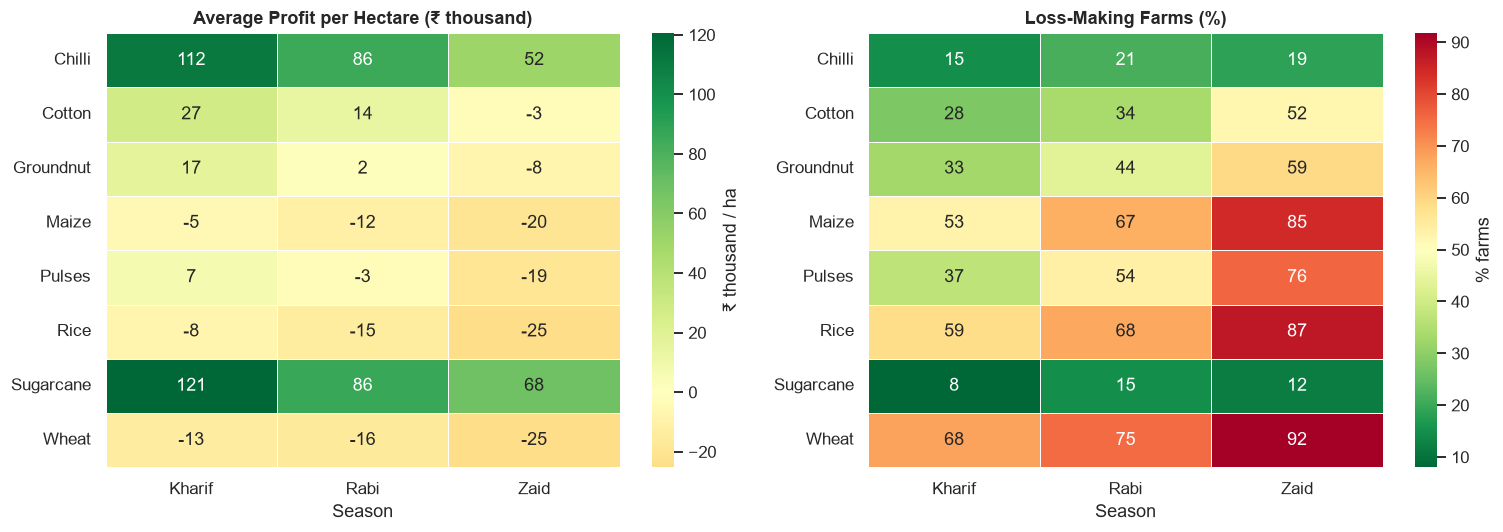

In [24]:
profit_cs = clean.pivot_table(index='Crop', columns='Season', values='Profit_per_ha', aggfunc='mean')[SEASON_ORDER]
loss_cs = clean.pivot_table(index='Crop', columns='Season', values='Loss_Making', aggfunc='mean')[SEASON_ORDER] * 100
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(profit_cs / 1000, annot=True, fmt='.0f', cmap='RdYlGn', center=0, linewidths=.5, cbar_kws={'label': '₹ thousand / ha'}, ax=ax[0])
ax[0].set_title('Average Profit per Hectare (₹ thousand)'); ax[0].set_ylabel('')
sns.heatmap(loss_cs, annot=True, fmt='.0f', cmap='RdYlGn_r', linewidths=.5, cbar_kws={'label': '% farms'}, ax=ax[1])
ax[1].set_title('Loss-Making Farms (%)'); ax[1].set_ylabel('')
save('06_crop_season_profit_heatmap'); plt.show()

**Insight Q5.** Market price does **not** differ by season (p ≈ 0.94), so the profit gap is driven by *yield*, not price. Average profit per hectare falls from **≈ ₹21.9k (Kharif) → ≈ ₹10.4k (Rabi) → ≈ –₹2.6k (Zaid)**, and the share of loss-making farms rises **42% → 51% → 64%**. Chilli and Sugarcane stay profitable in every season, while Wheat, Rice and Maize are loss-making for most farms — especially in Zaid.

### Q6 · Which seasonal conditions relate to yield?

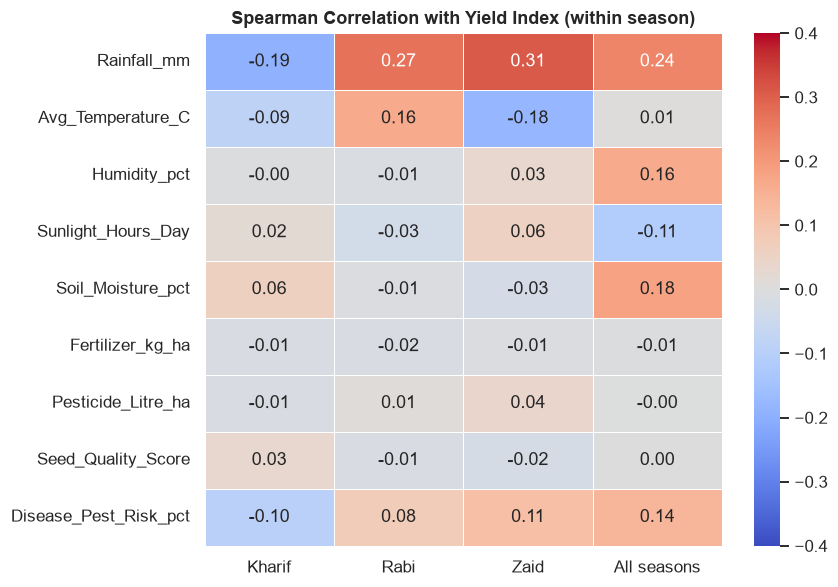

,Kharif,Rabi,Zaid,All seasons
Rainfall_mm,-0.191,0.271,0.308,0.240
Avg_Temperature_C,-0.086,0.163,-0.180,0.005
Humidity_pct,-0.004,-0.011,0.031,0.164
Sunlight_Hours_Day,0.021,-0.034,0.059,-0.113
Soil_Moisture_pct,0.060,-0.008,-0.025,0.183
Fertilizer_kg_ha,-0.014,-0.015,-0.008,-0.006
Pesticide_Litre_ha,-0.014,0.007,0.039,-0.001
Seed_Quality_Score,0.034,-0.014,-0.023,0.003
Disease_Pest_Risk_pct,-0.097,0.077,0.115,0.140


In [25]:
pred = ['Rainfall_mm', 'Avg_Temperature_C', 'Humidity_pct', 'Sunlight_Hours_Day', 'Soil_Moisture_pct',
        'Fertilizer_kg_ha', 'Pesticide_Litre_ha', 'Seed_Quality_Score', 'Disease_Pest_Risk_pct']
corr = pd.DataFrame({s: clean[clean.Season == s][pred + ['Yield_Index']].corr(method='spearman')['Yield_Index'].drop('Yield_Index') for s in SEASON_ORDER})
corr['All seasons'] = clean[pred + ['Yield_Index']].corr(method='spearman')['Yield_Index'].drop('Yield_Index')

fig, ax = plt.subplots(figsize=(8, 5.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-.4, vmax=.4, linewidths=.5, ax=ax)
ax.set_title('Spearman Correlation with Yield Index (within season)')
save('07_correlation_with_yield'); plt.show()
corr.round(3)

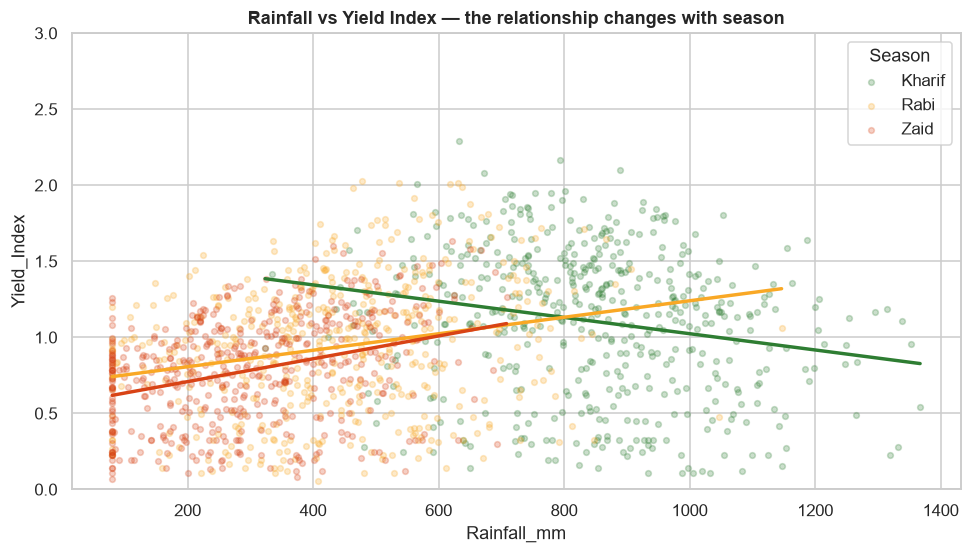

Kharif  Rainfall vs Yield Index: rho = -0.191, p = 0.0000
Rabi    Rainfall vs Yield Index: rho = +0.271, p = 0.0000
Zaid    Rainfall vs Yield Index: rho = +0.308, p = 0.0000


In [26]:
fig, ax = plt.subplots(figsize=(9, 5.2))
for s in SEASON_ORDER:
    d = clean[clean.Season == s]
    sns.regplot(data=d.sample(min(len(d), 500), random_state=1), x='Rainfall_mm', y='Yield_Index', scatter_kws={'alpha': .25, 's': 14}, color=PALETTE[s], label=s, ax=ax, ci=None, lowess=False)
ax.set_ylim(0, 3); ax.legend(title='Season'); ax.set_title('Rainfall vs Yield Index — the relationship changes with season')
save('08_rainfall_vs_yield_by_season'); plt.show()

for s in SEASON_ORDER:
    d = clean[clean.Season == s]; r, p = stats.spearmanr(d.Rainfall_mm, d.Yield_Index)
    print(f'{s:7s} Rainfall vs Yield Index: rho = {r:+.3f}, p = {p:.4f}')

**Insight Q6.** Within a season, individual factors explain only a small part of yield (|ρ| < 0.35) — farm-level yield is noisy. **Rainfall is the strongest correlate, and it changes sign**: negative in Kharif (ρ ≈ –0.19, a possible waterlogging/excess-water effect when rainfall is already high) and positive in Rabi/Zaid (ρ ≈ +0.27 / +0.31, where water is the limiting factor). Fertilizer, pesticide and seed-quality scores show essentially no relationship with yield in any season. These are associations, not proof of causation.

### Q7 · Does irrigation matter more in certain seasons?

Season             Kharif   Rabi   Zaid
Irrigation_Method                      
Drip                1.225  1.078  0.842
Flood               1.083  0.936  0.731
Rainfed             1.041  0.884  0.737
Sprinkler           1.114  0.948  0.882

Drip yield advantage over Rainfed (%): {'Kharif': 17.7, 'Rabi': 21.9, 'Zaid': 14.3}


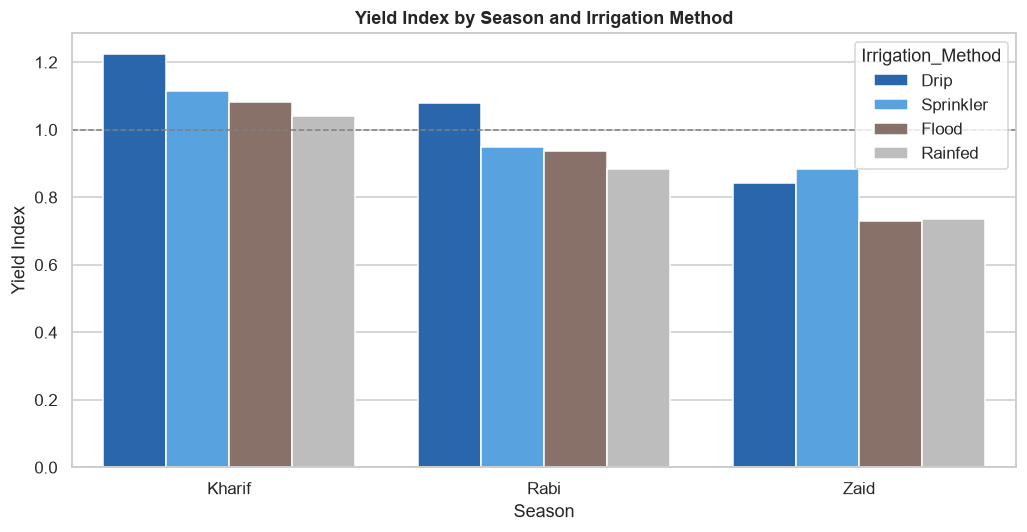

In [27]:
irr = clean.pivot_table(index='Irrigation_Method', columns='Season', values='Yield_Index', aggfunc='mean')[SEASON_ORDER]
irr['Drip_advantage_vs_Rainfed_%'] = None
print(irr.drop(columns='Drip_advantage_vs_Rainfed_%').round(3).to_string())
print()
adv = ((irr.loc['Drip', SEASON_ORDER].astype(float) / irr.loc['Rainfed', SEASON_ORDER].astype(float) - 1) * 100).round(1)
print('Drip yield advantage over Rainfed (%):', adv.to_dict())

fig, ax = plt.subplots(figsize=(9.5, 5))
sns.barplot(data=clean, x='Season', y='Yield_Index', hue='Irrigation_Method', order=SEASON_ORDER,
            hue_order=['Drip', 'Sprinkler', 'Flood', 'Rainfed'], palette=['#1565C0', '#42A5F5', '#8D6E63', '#BDBDBD'], errorbar=None, ax=ax)
ax.axhline(1, ls='--', c='grey', lw=1); ax.set_title('Yield Index by Season and Irrigation Method'); ax.set_ylabel('Yield Index')
save('09_irrigation_by_season'); plt.show()

In [28]:
# Test whether irrigation method affects yield within each season
for s in SEASON_ORDER:
    d = clean[clean.Season == s]
    H, p = stats.kruskal(*[d.loc[d.Irrigation_Method == m, 'Yield_Index'] for m in d.Irrigation_Method.unique()])
    print(f'{s:7s} irrigation effect: H = {H:6.1f}, p = {p:.2e}')

Kharif  irrigation effect: H =   38.8, p = 1.96e-08
Rabi    irrigation effect: H =   43.6, p = 1.85e-09
Zaid    irrigation effect: H =   19.7, p = 1.92e-04


**Insight Q7.** Irrigation method makes a statistically significant difference in **every** season (p < 0.001). **Drip is the best method in Kharif and Rabi** (advantage over rainfed: +18% and +22%), while in **Zaid sprinkler leads (0.88) followed by drip (0.84)** — both clearly ahead of flood/rainfed (≈ 0.73–0.74). Micro-irrigation (drip/sprinkler) also has the lowest loss-making share in Zaid (54–60% vs 66–75% for flood/rainfed).

### Q8 · Are the patterns consistent across states?

States following Kharif > Rabi > Zaid: 8 of 8


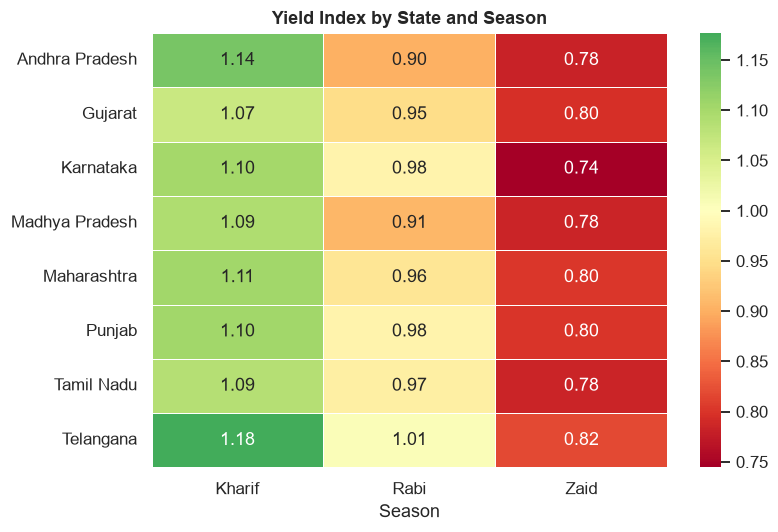

Season,Kharif,Rabi,Zaid,Kharif>Rabi>Zaid
State,,,,
Andhra Pradesh,1.139,0.900,0.782,True
Gujarat,1.067,0.948,0.796,True
Karnataka,1.102,0.981,0.744,True
Madhya Pradesh,1.091,0.908,0.784,True
Maharashtra,1.105,0.960,0.803,True
Punjab,1.104,0.982,0.800,True
Tamil Nadu,1.087,0.972,0.784,True
Telangana,1.177,1.006,0.818,True


In [29]:
state_season = clean.pivot_table(index='State', columns='Season', values='Yield_Index', aggfunc='mean')[SEASON_ORDER]
state_season['Kharif>Rabi>Zaid'] = (state_season.Kharif > state_season.Rabi) & (state_season.Rabi > state_season.Zaid)
print('States following Kharif > Rabi > Zaid:', int(state_season['Kharif>Rabi>Zaid'].sum()), 'of', len(state_season))

fig, ax = plt.subplots(figsize=(7.5, 5))
sns.heatmap(state_season[SEASON_ORDER], annot=True, fmt='.2f', cmap='RdYlGn', center=1, linewidths=.5, ax=ax)
ax.set_title('Yield Index by State and Season'); ax.set_ylabel('')
save('10_state_season_heatmap'); plt.show()
state_season.round(3)

**Insight Q8.** All 8 states show the same Kharif > Rabi > Zaid ordering — the seasonal pattern is **geographically consistent**. State differences within a season are small compared with the seasonal gap.

### Q9 · Unusual or unexpected patterns

In [30]:
odd = clean.groupby('Season').agg(Disease_Risk=('Disease_Pest_Risk_pct', 'mean'), Yield_Index=('Yield_Index', 'mean'),
                                  Water_per_ha=('Water_per_ha', 'mean'), Water_Eff=('Water_Efficiency_t_per_1000m3', 'mean')).round(2)
odd

,Disease_Risk,Yield_Index,Water_per_ha,Water_Eff
Season,,,,
Kharif,54.47,1.11,758.17,5.89
Rabi,40.48,0.96,763.36,5.19
Zaid,38.22,0.79,792.58,4.41


1. **Highest disease/pest risk coincides with the highest yield (Kharif).** Risk is ≈ 54% in Kharif vs ≈ 38% in Zaid, yet Kharif yields most. Favourable moisture and rainfall appear to outweigh pest pressure — but it also means Kharif crops are carrying more preventable risk.
2. **Identical inputs, unequal outcomes.** Zaid gets the same fertilizer, pesticide, water and cost per hectare as Kharif but yields ≈ 29% less, leading to the highest loss-making share (64%).
3. **Rainfall flips from harmful to helpful** across seasons (Q6).
4. **Price is flat across seasons** — there is no seasonal price premium compensating for Zaid's lower yield.
5. **Staples underperform economically:** Wheat and Rice are loss-making on ≈ 87–92% of farms in Zaid because their per-tonne prices (~₹22–24k) do not cover per-hectare costs at typical yields.

## 6.1 Presentation-ready figures
Compact, large-font versions of the key charts used in the project presentation (saved to `images/ppt_*.png`).

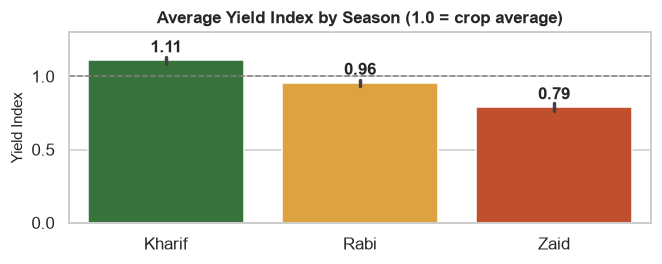

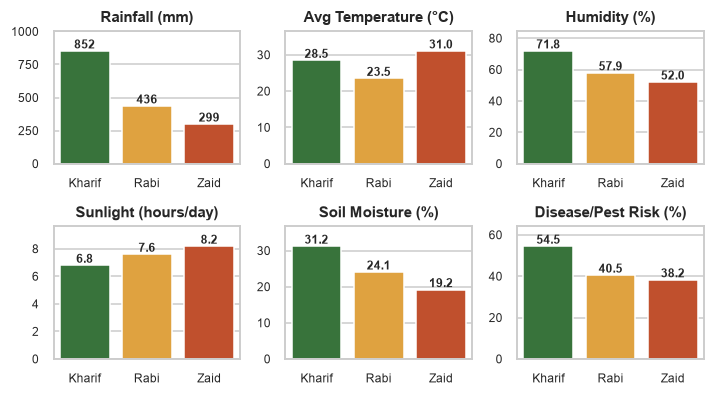

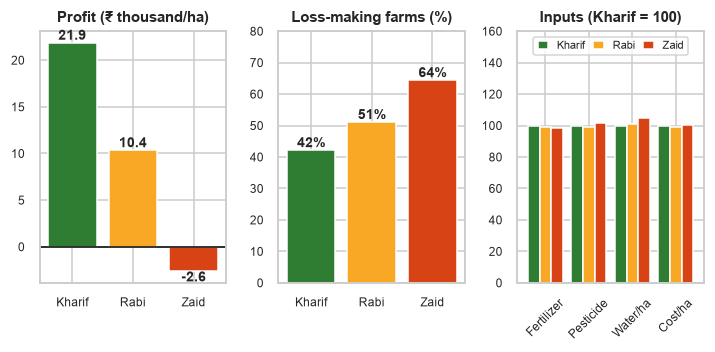

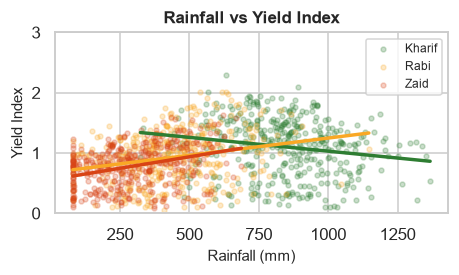

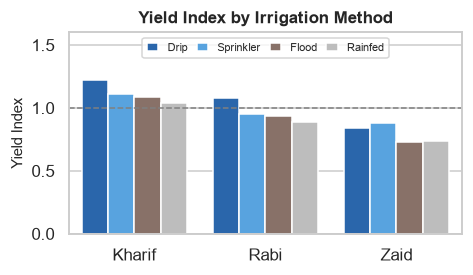

In [31]:
with plt.rc_context({'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.labelsize': 10}):
    # 1) Yield index by season
    fig, ax = plt.subplots(figsize=(6.2, 2.5))
    sns.barplot(data=clean, x='Season', y='Yield_Index', order=SEASON_ORDER, palette=PALETTE, hue='Season', hue_order=SEASON_ORDER, dodge=False, legend=False, errorbar=('ci', 95), ax=ax)
    ax.axhline(1, ls='--', c='grey', lw=1); ax.set_title('Average Yield Index by Season (1.0 = crop average)')
    ax.set_xlabel(''); ax.set_ylabel('Yield Index'); ax.set_ylim(0, 1.3)
    for p in ax.patches: ax.annotate(f'{p.get_height():.2f}', (p.get_x() + p.get_width() / 2, p.get_height() + .03), ha='center', va='bottom', fontweight='bold', fontsize=11)
    save('ppt_1_yield_index'); plt.show()

    # 2) Environment
    fig, axes = plt.subplots(2, 3, figsize=(6.6, 3.7))
    for ax, c in zip(axes.ravel(), env_cols):
        sns.barplot(data=clean, x='Season', y=c, order=SEASON_ORDER, palette=PALETTE, hue='Season', hue_order=SEASON_ORDER, dodge=False, legend=False, errorbar=None, ax=ax)
        ax.set_title(titles[c], fontsize=9.5); ax.set_xlabel(''); ax.set_ylabel(''); ax.tick_params(labelsize=8)
        for p in ax.patches: ax.annotate(f'{p.get_height():.0f}' if p.get_height() > 100 else f'{p.get_height():.1f}', (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom', fontsize=8, fontweight='bold')
        ax.set_ylim(0, ax.get_ylim()[1] * 1.12)
    save('ppt_2_environment'); plt.show()

    # 3) Economics + input usage
    fig, ax = plt.subplots(1, 3, figsize=(6.6, 3.3))
    prof = clean.groupby('Season').Profit_per_ha.mean() / 1000
    ax[0].bar(SEASON_ORDER, prof.reindex(SEASON_ORDER), color=[PALETTE[s] for s in SEASON_ORDER]); ax[0].axhline(0, c='black', lw=1)
    ax[0].set_title('Profit (₹ thousand/ha)', fontsize=9.5)
    for i, v in enumerate(prof.reindex(SEASON_ORDER)): ax[0].annotate(f'{v:.1f}', (i, v), ha='center', va='bottom' if v > 0 else 'top', fontsize=9, fontweight='bold')
    loss = clean.groupby('Season').Loss_Making.mean().reindex(SEASON_ORDER) * 100
    ax[1].bar(SEASON_ORDER, loss, color=[PALETTE[s] for s in SEASON_ORDER]); ax[1].set_ylim(0, 80); ax[1].set_title('Loss-making farms (%)', fontsize=9.5)
    for i, v in enumerate(loss): ax[1].annotate(f'{v:.0f}%', (i, v), ha='center', va='bottom', fontsize=9, fontweight='bold')
    inp = clean.groupby('Season')[['Fertilizer_kg_ha', 'Pesticide_Litre_ha', 'Water_per_ha', 'Cost_per_ha']].mean()
    inp = (inp / inp.loc['Kharif'] * 100).reindex(SEASON_ORDER).T
    inp.index = ['Fertilizer', 'Pesticide', 'Water/ha', 'Cost/ha']
    inp.plot.bar(ax=ax[2], color=[PALETTE[s] for s in SEASON_ORDER], width=.8, legend=False)
    ax[2].set_ylim(0, 160); ax[2].set_title('Inputs (Kharif = 100)', fontsize=9.5); ax[2].tick_params(axis='x', rotation=45)
    ax[2].legend(SEASON_ORDER, fontsize=7, ncol=3, loc='upper center', columnspacing=.8, handlelength=1)
    for a in ax: a.tick_params(labelsize=8); a.set_xlabel('')
    save('ppt_3_economics'); plt.show()

    # 4) Rainfall vs yield by season
    fig, ax = plt.subplots(figsize=(4.4, 2.6))
    for s in SEASON_ORDER:
        d = clean[clean.Season == s]
        sns.regplot(data=d.sample(min(len(d), 400), random_state=1), x='Rainfall_mm', y='Yield_Index', scatter_kws={'alpha': .25, 's': 10}, color=PALETTE[s], label=s, ax=ax, ci=None)
    ax.set_ylim(0, 3); ax.legend(fontsize=8, loc='upper right'); ax.set_title('Rainfall vs Yield Index'); ax.set_xlabel('Rainfall (mm)'); ax.set_ylabel('Yield Index')
    save('ppt_4_rainfall'); plt.show()

    # 5) Irrigation
    fig, ax = plt.subplots(figsize=(4.4, 2.6))
    sns.barplot(data=clean, x='Season', y='Yield_Index', hue='Irrigation_Method', order=SEASON_ORDER, hue_order=['Drip', 'Sprinkler', 'Flood', 'Rainfed'],
                palette=['#1565C0', '#42A5F5', '#8D6E63', '#BDBDBD'], errorbar=None, ax=ax)
    ax.axhline(1, ls='--', c='grey', lw=1); ax.set_ylim(0, 1.6); ax.set_title('Yield Index by Irrigation Method'); ax.set_xlabel(''); ax.set_ylabel('Yield Index')
    ax.legend(fontsize=7.5, ncol=4, loc='upper center', title=None, columnspacing=.8, handlelength=1)
    save('ppt_5_irrigation'); plt.show()

## 7. Conclusions
1. **Season is a consistent, statistically robust driver of performance.** Yield Index: Kharif 1.11 → Rabi 0.96 → Zaid 0.79 (p ≪ 0.001), identical in direction for every crop and every state. Season alone explains ≈ 6% of farm-level variance (η² = 0.061), so farm-to-farm variability remains large.
2. **Environmental conditions differ sharply**: Kharif is wet/humid/high-pest, Rabi cool and moderate, Zaid hot/dry/sunny.
3. **Farmers do not adjust inputs by season** — fertilizer, pesticide, water and cost per hectare are the same across seasons.
4. **Economics follow yield, not price.** Profit/ha falls from ≈ ₹21.9k to –₹2.6k; loss-making farms rise from 42% to 64%.
5. **Micro-irrigation** (drip in Kharif/Rabi, sprinkler in Zaid) consistently delivers the best yields and the fewest loss-making farms in the drier seasons.
6. **Rainfall acts differently by season** — excess is associated with lower yield in Kharif; scarcity limits yield in Rabi/Zaid.

## 8. Recommendations
| # | Recommendation | Evidence |
|---|---|---|
| 1 | Plan crop portfolios seasonally — **Chilli and Sugarcane** stay profitable in all seasons (Cotton only in Kharif/Rabi); treat Wheat, Rice and Maize in Zaid as high-risk | Crop × season profit heatmap |
| 2 | Prioritise **drip irrigation in Kharif/Rabi and sprinkler/drip in Zaid** over flood or rainfed | Yield Index by irrigation × season |
| 3 | Introduce **season-specific input plans** (heat/drought management in Zaid, drainage & pest control in Kharif) | Inputs identical across seasons but outcomes not |
| 4 | Strengthen **pest surveillance in Kharif**, when disease risk peaks | Kharif risk ≈ 54% |
| 5 | Improve **drainage** on high-rainfall Kharif farms | Negative rainfall–yield link in Kharif |
| 6 | Investigate the **cost/price gap for Wheat & Rice** (loss-making on most farms) | Loss-making share 59–92% |
| 7 | Use the **Yield Index** and seasonal benchmarks for evidence-based planning and monitoring | This analysis |

## 9. Limitations & Future Work
- The data appears **synthetic** (e.g. district names are not consistent with states), so real-world generalisation should be validated with actual records.
- Only one observation per farm (cross-sectional): **year-to-year** trends cannot be studied.
- Associations are not proof of causation.
- Future: predictive yield/profit models, time-series data, an interactive dashboard, crop-recommendation system.